In [1]:
# Import required libraries for data analysis and visualization
import os, glob, pandas as pd, seaborn as sns, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

In [2]:
import re

# Load master heatmap CSV files from current directory
csv_files = glob.glob("master_heatmap*.csv")  # Find all CSV files in current directory

def extract_teff_bin(filename):
    match = re.search(r'(\d{4})_(\d{4})_K', filename)
    if match:
        return f"{match.group(1)}_{match.group(2)}"
    return None

# Load and combine all CSV files into a single dataframe, adding temperature bin
df = pd.DataFrame()
for f in csv_files:
    temp_bin = extract_teff_bin(f)
    temp_df = pd.read_csv(f)
    temp_df['teff_bin'] = temp_bin
    df = pd.concat([df, temp_df], ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(df.head())



Combined dataframe shape: (336, 7)
Columns: ['radius_bin_center', 'period_bin_center', 'detections', 'trials', 'transit_prob', 'detection_rate', 'teff_bin']
   radius_bin_center  period_bin_center  detections  trials  transit_prob  \
0           1.923851           0.786000          36      41      0.224285   
1           1.923851           1.336168          25      32      0.159290   
2           1.923851           2.271888          24      29      0.109199   
3           1.923851           3.863276          29      42      0.081758   
4           1.923851           6.569863          22      36      0.055315   

   detection_rate   teff_bin  
0        0.878049  4000_4500  
1        0.781250  4000_4500  
2        0.827586  4000_4500  
3        0.690476  4000_4500  
4        0.611111  4000_4500  


Period values: [ 0.786       1.33616763  2.2718882   3.86327637  6.56986297 11.17286733
 18.99781387]
Period log values: [-0.10457745  0.12586095  0.35638696  0.58695578  0.81755631  1.04816464
  1.27870363]
Period bin edges: [0.6028417826212565, 1.0248062058899103, 1.7423040703393378, 2.9625887317403348, 5.037975426914379, 8.567625539322146, 14.56914733367361, 24.772687354491236]
Number of bins: 7


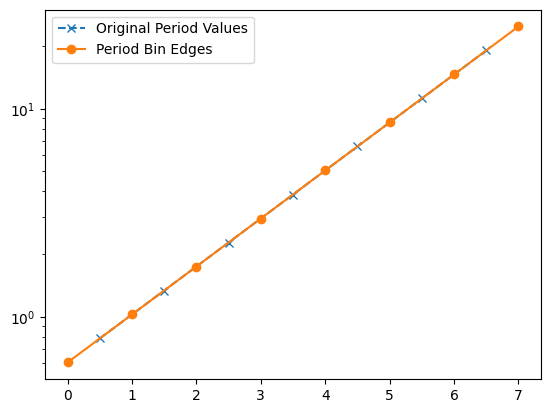

Radius values: [1.92385113 2.1977049  2.51054084 2.86790793 3.27614504 3.74249332]
Radius log values: [0.28417146 0.34196938 0.39976729 0.45756521 0.51536312 0.57316103]
Radius bin edges: [1.7999999999999998, 2.056223979157517, 2.348920584701318, 2.6832815729997477, 3.065237729574213, 3.501564067427134, 3.999999999999999]
Number of bins: 6


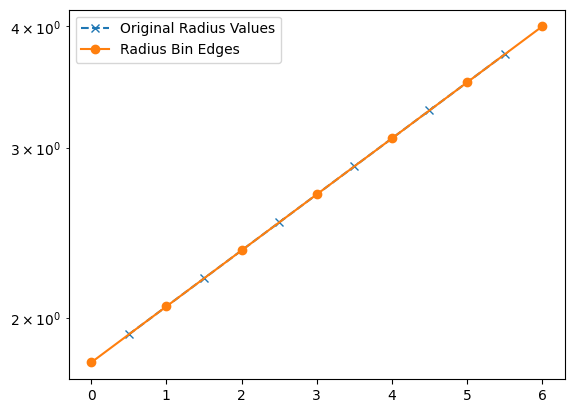

In [3]:
# Generate log-spaced bin edges for True Period values
period_vals = np.array(sorted(df['period_bin_center'].unique()))  # Get unique period values

# Calculate log-space halfway points between adjacent values
period_log = np.log10(period_vals)  # Convert to log space
period_bin_edges = []

# First edge: extrapolate backward using same log spacing as first interval
log_step = period_log[1] - period_log[0]  # Log spacing between first two values
first_edge = 10**(period_log[0] - log_step/2)  # Extrapolate backward by half step
period_bin_edges.append(first_edge)

# Middle edges: halfway points in log space between adjacent values
for i in range(len(period_log) - 1):
    halfway_log = (period_log[i] + period_log[i+1]) / 2  # Midpoint in log space
    period_bin_edges.append(10**halfway_log)  # Convert back to linear space

# Last edge: extrapolate forward using same log spacing as last interval
log_step = period_log[-1] - period_log[-2]  # Log spacing between last two values
last_edge = 10**(period_log[-1] + log_step/2)  # Extrapolate forward by half step
period_bin_edges.append(last_edge)

# Print results for verification
print(f"Period values: {period_vals}")
print(f"Period log values: {period_log}")
print(f"Period bin edges: {period_bin_edges}")
print(f"Number of bins: {len(period_bin_edges) - 1}")

# Plot to visualize period values vs bin edges
period_vals_x_axis = np.arange(len(period_vals)) + 0.5  # Offset for visualization
plt.plot(period_vals_x_axis, period_vals, 'x--', label='Original Period Values')
plt.plot(period_bin_edges, 'o-', label='Period Bin Edges')
plt.legend()
plt.yscale('log')  # Log scale for better visualization
plt.show()

# Generate log-spaced bin edges for True Radius values (same method as periods)
radius_vals = np.array(sorted(df['radius_bin_center'].unique()))  # Get unique radius values

# Calculate log-space halfway points between adjacent values
radius_log = np.log10(radius_vals)  # Convert to log space
radius_bin_edges = []

# First edge: extrapolate backward using same log spacing as first interval
log_step = radius_log[1] - radius_log[0]  # Log spacing between first two values
first_edge = 10**(radius_log[0] - log_step/2)  # Extrapolate backward by half step
radius_bin_edges.append(first_edge)

# Middle edges: halfway points in log space between adjacent values
for i in range(len(radius_log) - 1):
    halfway_log = (radius_log[i] + radius_log[i+1]) / 2  # Midpoint in log space
    radius_bin_edges.append(10**halfway_log)  # Convert back to linear space

# Last edge: extrapolate forward using same log spacing as last interval
log_step = radius_log[-1] - radius_log[-2]  # Log spacing between last two values
last_edge = 10**(radius_log[-1] + log_step/2)  # Extrapolate forward by half step
radius_bin_edges.append(last_edge)

# Print results for verification
print(f"Radius values: {radius_vals}")
print(f"Radius log values: {radius_log}")
print(f"Radius bin edges: {radius_bin_edges}")
print(f"Number of bins: {len(radius_bin_edges) - 1}")

# Plot to visualize radius values vs bin edges
radius_vals_x_axis = np.arange(len(radius_vals)) + 0.5  # Offset for visualization
plt.plot(radius_vals_x_axis, radius_vals, 'x--', label='Original Radius Values')
plt.plot(radius_bin_edges, 'o-', label='Radius Bin Edges')
plt.legend()
plt.yscale('log')  # Log scale for better visualization
plt.show()



In [4]:
# Assign bin min/max edges for each row using pd.cut with labels as bin index, then map to edge values
df['radius_bin'] = pd.cut(df['radius_bin_center'], bins=radius_bin_edges, include_lowest=True, labels=False)
df['period_bin'] = pd.cut(df['period_bin_center'], bins=period_bin_edges, include_lowest=True, labels=False)
df['radius_bin_min'] = df['radius_bin'].apply(lambda x: radius_bin_edges[int(x)] if pd.notnull(x) else np.nan)
df['radius_bin_max'] = df['radius_bin'].apply(lambda x: radius_bin_edges[int(x)+1] if pd.notnull(x) else np.nan)
df['period_bin_min'] = df['period_bin'].apply(lambda x: period_bin_edges[int(x)] if pd.notnull(x) else np.nan)
df['period_bin_max'] = df['period_bin'].apply(lambda x: period_bin_edges[int(x)+1] if pd.notnull(x) else np.nan)
print(df.head())

   radius_bin_center  period_bin_center  detections  trials  transit_prob  \
0           1.923851           0.786000          36      41      0.224285   
1           1.923851           1.336168          25      32      0.159290   
2           1.923851           2.271888          24      29      0.109199   
3           1.923851           3.863276          29      42      0.081758   
4           1.923851           6.569863          22      36      0.055315   

   detection_rate   teff_bin  radius_bin  period_bin  radius_bin_min  \
0        0.878049  4000_4500           0           0             1.8   
1        0.781250  4000_4500           0           1             1.8   
2        0.827586  4000_4500           0           2             1.8   
3        0.690476  4000_4500           0           3             1.8   
4        0.611111  4000_4500           0           4             1.8   

   radius_bin_max  period_bin_min  period_bin_max  
0        2.056224        0.602842        1.024806  


687


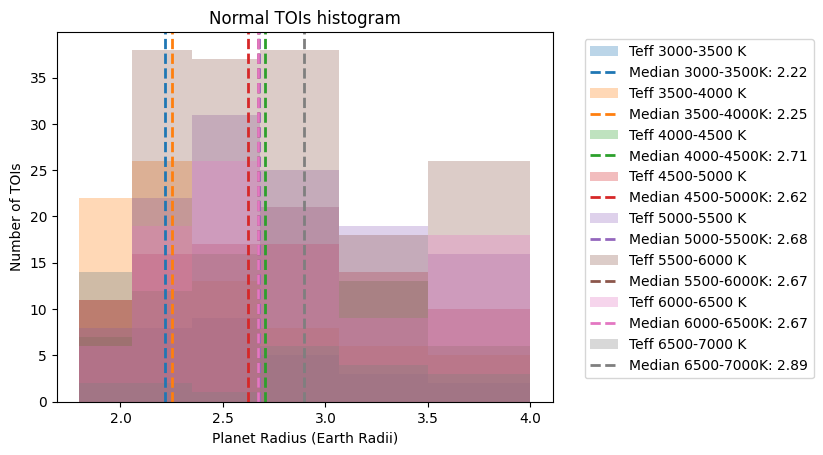

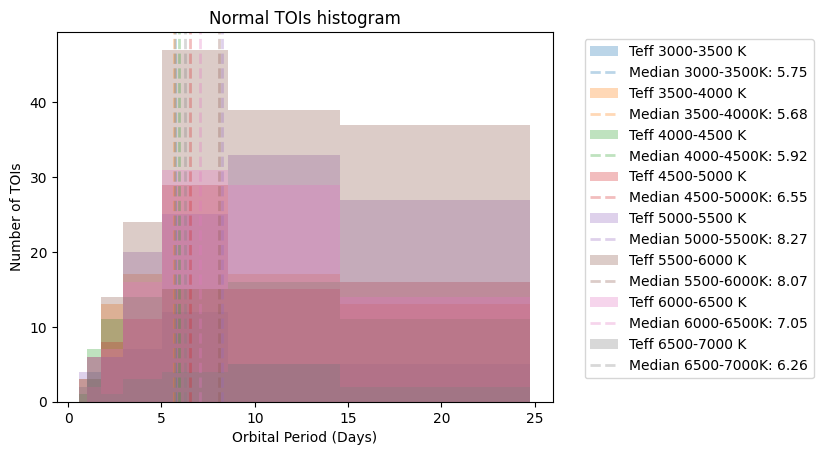

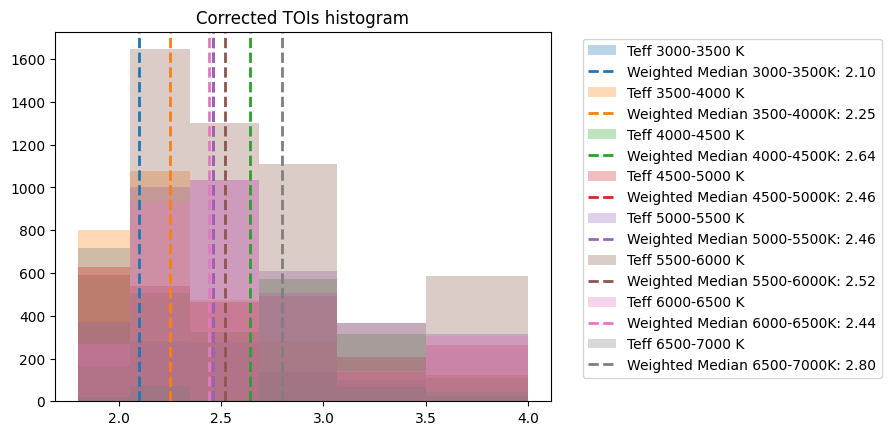

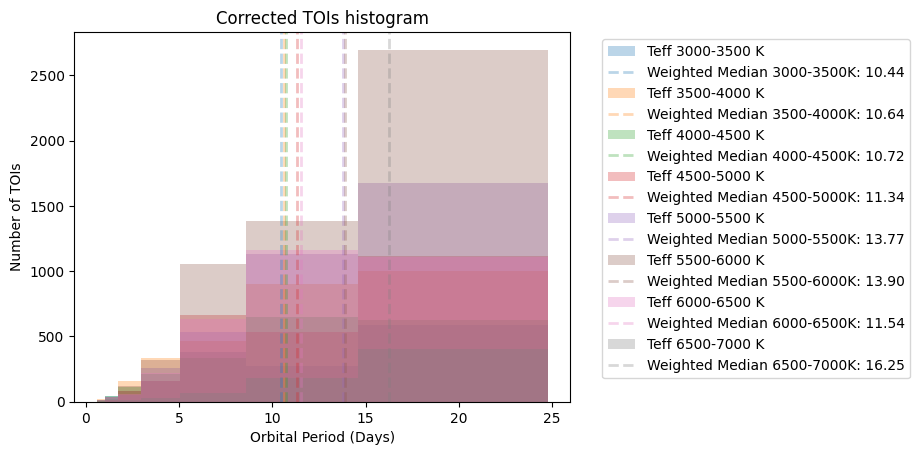

Rows with any NaNs in merged_df: 1
Rows with NaNs in merged_df:
         toi  st_teff  pl_rade  pl_orbper   teff_bin  radius_bin_min  \
612  1873.01   5699.0  3.93465  24.934188  5500_6000        3.501564   

     radius_bin_max  period_bin_min  period_bin_max  radius_bin_center  \
612             4.0             NaN             NaN                NaN   

     period_bin_center  detections  trials  transit_prob  detection_rate  \
612                NaN         NaN     NaN           NaN             NaN   

     radius_bin  period_bin  detection_inverse  transit_inverse  weight  
612         NaN         NaN                NaN              NaN     1.0  
         toi  st_teff   pl_rade  pl_orbper   teff_bin  radius_bin_min  \
0    5165.01  4642.10  3.300100   3.577501  4500_5000        3.065238   
1    6944.01  5181.10  2.609860  12.302750  5000_5500        2.348921   
2    5789.01  5132.00  2.537040  12.925605  5000_5500        2.348921   
3    5319.01  3580.00  3.746810   4.078527  3500_

In [5]:
 
TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')

# Define temperature ranges matching our completeness data
teff_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), 
               (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]

#teff_ranges = [(t, t + 1000) for t in range(3000, 7000, 1000)]

# Filter TOIs data
TOIs_filtered = TOIs.dropna(subset=['st_teff', 'pl_rade'])
#print(len(TOIs_filtered))

TOIs_filtered = TOIs_filtered[(TOIs_filtered['pl_rade'] > 1.8) & (TOIs_filtered['pl_rade'] < 4.0)]
TOIs_filtered = TOIs_filtered[(TOIs_filtered['pl_orbper'] > 0.6028) & (TOIs_filtered['pl_orbper'] < 25.1)]
#TOIs_bootstrap = TOIs_bootstrap[~TOIs_bootstrap['toi'].isin([2194.01])] #second try ones with giant corrections

#TOIs_filtered = TOIs_filtered[~TOIs_filtered['id'].isin([80224448, 370009806])] # The ones with giant corrections
#TOIs_filtered = TOIs_filtered[~TOIs_filtered['toi'].isin([2482.01, 2194.01, 2103.02])] #second try ones with giant corrections
#TOIs_filtered = TOIs_filtered[~TOIs_filtered['toi'].isin([2194.01])] #second try ones with giant corrections
#TOIs_filtered = TOIs_filtered[TOIs_filtered['tfopwg_disp'] != 'FA']


#TOIs_filtered = TOIs_filtered[(TOIs_filtered['ruwe'] <= 1.4)]

# Remove false positives if column exists
if 'tfopwg_disp' in TOIs_filtered.columns:
    TOIs_filtered = TOIs_filtered[TOIs_filtered['tfopwg_disp'] != 'FP']

TOIs_filtered = TOIs_filtered[['toi', 'st_teff', 'pl_rade', 'pl_orbper']]

radius_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]

period_bins = [(period_bin_edges[i], period_bin_edges[i+1]) for i in range(len(period_bin_edges)-1)]
print(len(TOIs_filtered))

#print(radius_bins)
#print(period_bins)

for row in TOIs_filtered.itertuples():
    teff = row.st_teff
    radius = row.pl_rade
    period = row.pl_orbper
    
    # Determine which temperature bin the TOI falls into
    for teff_min, teff_max in teff_ranges:
        if teff_min <= teff < teff_max:
            teff_bin = f"{teff_min}_{teff_max}"
            TOIs_filtered.at[row.Index, 'teff_bin'] = teff_bin
    
    for rad_min, rad_max in radius_bins:
        if rad_min <= radius < rad_max:
            radius_bin_min = rad_min
            radius_bin_max = rad_max
            TOIs_filtered.at[row.Index, 'radius_bin_min'] = radius_bin_min
            TOIs_filtered.at[row.Index, 'radius_bin_max'] = radius_bin_max

    for per_min, per_max in period_bins:
        if per_min <= period < per_max:
            period_bin_min = per_min
            period_bin_max = per_max
            TOIs_filtered.at[row.Index, 'period_bin_min'] = period_bin_min
            TOIs_filtered.at[row.Index, 'period_bin_max'] = period_bin_max

#print(TOIs_filtered)
  
# Merge TOIs with completeness data
merged_df = pd.merge(TOIs_filtered, df, on=['teff_bin', 'radius_bin_min', 'radius_bin_max', 'period_bin_min', 'period_bin_max'], how='left')
#print(merged_df)

#### REGULAR HISTOGRAM
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_rade'], bins=radius_bin_edges, alpha=.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K')
    hist_color = patches[0].get_facecolor()
    median_val = teff_df['pl_rade'].median()
    plt.axvline(median_val, linestyle='--', linewidth=2, color=hist_color, label=f'Median {temp_range[0]}-{temp_range[1]}K: {median_val:.2f}', alpha=1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Planet Radius (Earth Radii)')
    plt.ylabel('Number of TOIs')
    plt.title('Normal TOIs histogram')
plt.show()

for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_orbper'], bins=period_bin_edges, alpha=0.3, label=f'Teff {temp_range[0]}-{temp_range[1]} K')
    hist_color = patches[0].get_facecolor()
    median_val = teff_df['pl_orbper'].median()
    plt.axvline(median_val, linestyle='--', linewidth=2, color=hist_color, label=f'Median {temp_range[0]}-{temp_range[1]}K: {median_val:.2f}')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Orbital Period (Days)')
    plt.ylabel('Number of TOIs')
    plt.title('Normal TOIs histogram')
plt.show()
########

# calculate inverse detection and transit probabilities
for row in merged_df.itertuples():
    detection_rate = row.detection_rate
    transit_prob = row.transit_prob

    # Only update detection_inverse and transit_inverse, leave other columns untouched
    if pd.notnull(detection_rate) and detection_rate > 0:
        merged_df.at[row.Index, 'detection_inverse'] = 1/detection_rate
    else:
        merged_df.at[row.Index, 'detection_inverse'] = np.nan

    if pd.notnull(transit_prob) and transit_prob > 0:
        merged_df.at[row.Index, 'transit_inverse'] = 1/transit_prob
    else:
        merged_df.at[row.Index, 'transit_inverse'] = np.nan
#print(merged_df)

#merged_df to csv
#merged_df[['toi', 'detection_inverse', 'transit_inverse']].to_csv('merged_df.csv', index=False)

# Duplicate each row of merged_df according to a per-row count value in a new column 'row_count'
# First, define how you want to calculate 'weight' for each row. 
# Example: here we use detection_inverse * transit_inverse rounded to nearest int, but you can change this logic.
merged_df['weight'] = (merged_df['detection_inverse'] * merged_df['transit_inverse']).fillna(1)
#merged_df['mult_count'] = np.where(merged_df['mult_count'] >= 1, merged_df['mult_count'] - 1, merged_df['mult_count'])
#print(merged_df[['toi', 'detection_rate', 'transit_prob', 'detection_inverse', 'transit_inverse', 'mult_count']])

#print(merged_df)
#print(merged_df[['toi', 'detection_inverse', 'transit_inverse', 'row_count']])
# Now repeat each row according to its 'row_count' value
#merged_df_corrected = merged_df#.loc[merged_df.index.repeat(merged_df['mult_count'])].reset_index(drop=True)

radius_medians = pd.DataFrame(columns=['Teff Range', 'Weighted Median Radius (Earth Radii)'])
###CORRECTED HISTOGRAM
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_rade'], bins=radius_bin_edges, alpha=0.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K', weights=teff_df['weight'])
    hist_color = patches[0].get_facecolor()
    # Calculate weighted median
    vals = teff_df['pl_rade'].values
    weights = teff_df['weight'].values
    if len(vals) > 0 and weights.sum() > 0:
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        weights_sorted = weights[sorted_idx]
        cumsum = np.cumsum(weights_sorted)
        cutoff = weights_sorted.sum() / 2.0
        weighted_median = vals_sorted[np.searchsorted(cumsum, cutoff)]
        radius_medians = pd.concat([
            radius_medians,
            pd.DataFrame({
            'Teff Range': [f"{temp_range[0]}-{temp_range[1]}K"],
            'Weighted Median Radius (Earth Radii)': [weighted_median]
            })], ignore_index=True)
        plt.axvline(weighted_median, linestyle='--', linewidth=2, color=hist_color, label=f'Weighted Median {temp_range[0]}-{temp_range[1]}K: {weighted_median:.2f}', alpha=1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title('Corrected TOIs histogram')
plt.show()

#radius_medians.to_csv('corrected_medians.csv', index=False)

for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_orbper'], bins=period_bin_edges, alpha=0.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K', weights=teff_df['weight'])
    hist_color = patches[0].get_facecolor()
    # Calculate weighted median
    vals = teff_df['pl_orbper'].values
    weights = teff_df['weight'].values
    if len(vals) > 0 and weights.sum() > 0:
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        weights_sorted = weights[sorted_idx]
        cumsum = np.cumsum(weights_sorted)
        cutoff = weights_sorted.sum() / 2.0
        weighted_median = vals_sorted[np.searchsorted(cumsum, cutoff)]
        plt.axvline(weighted_median, linestyle='--', linewidth=2, color=hist_color, label=f'Weighted Median {temp_range[0]}-{temp_range[1]}K: {weighted_median:.2f}')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Orbital Period (Days)')
    plt.ylabel('Number of TOIs')
    plt.title('Corrected TOIs histogram')
plt.show()
#######

#print how many rows have NaNs in merged_df
print("Rows with any NaNs in merged_df:", merged_df.isnull().any(axis=1).sum())
print("Rows with NaNs in merged_df:")
print(merged_df[merged_df.isnull().any(axis=1)])
print(merged_df)

687 TOIs for bootstrapping


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


   Teff Range  Weighted Median Radius (Earth Radii)  \
0  3000-3500K                              2.102385   
1  3500-4000K                              2.249375   
2  4000-4500K                              2.640320   
3  4500-5000K                              2.460344   
4  5000-5500K                              2.461646   
5  5500-6000K                              2.519480   
6  6000-6500K                              2.443170   
7  6500-7000K                              2.797790   

   Weighted Median Error (Earth Radii)  
0                             0.103644  
1                             0.038079  
2                             0.081624  
3                             0.093032  
4                             0.043977  
5                             0.056888  
6                             0.041673  
7                             0.102650  


(-0.0, 0.07)

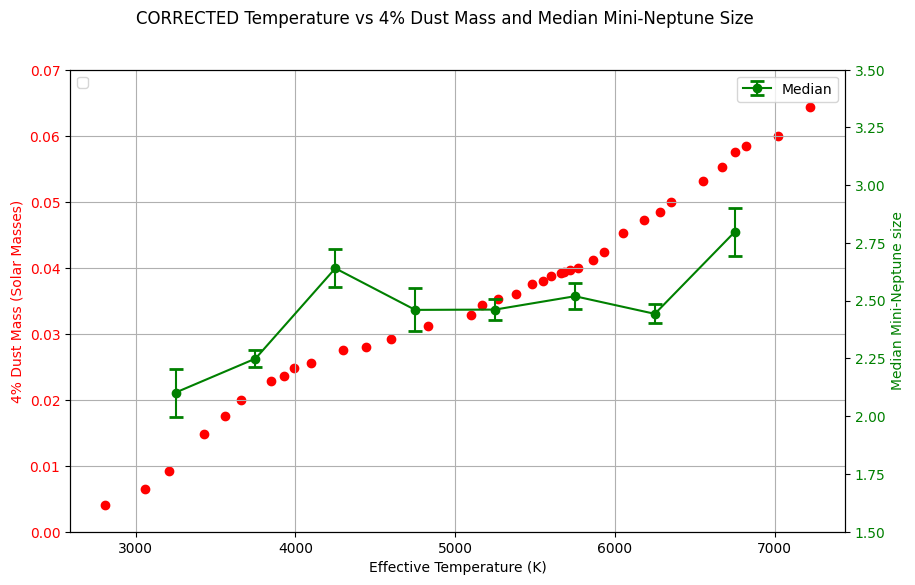

In [6]:
n_bootstrap = 1000
teff_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), 
               (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]

# Calculate bootstrapping errors for weighted medians
def calculate_weighted_median(vals, weights):
    """Calculate weighted median"""
    if len(vals) == 0 or weights.sum() == 0:
        return np.nan
    sorted_idx = np.argsort(vals)
    vals_sorted = vals[sorted_idx]
    weights_sorted = weights[sorted_idx]
    cumsum = np.cumsum(weights_sorted)
    cutoff = weights_sorted.sum() / 2.0
    return vals_sorted[np.searchsorted(cumsum, cutoff)]

# Load TOI data for bootstrapping
TOIs_bootstrap = TOIs_filtered
TOIs_bootstrap = TOIs_bootstrap.dropna(subset=['st_teff', 'pl_rade'])
TOIs_bootstrap = TOIs_bootstrap[(TOIs_bootstrap['pl_rade'] > 1.8) & (TOIs_bootstrap['pl_rade'] < 4.0)]
TOIs_bootstrap = TOIs_bootstrap[(TOIs_bootstrap['pl_orbper'] > 0.6028) & (TOIs_bootstrap['pl_orbper'] < 25.1)]
#TOIs_bootstrap = TOIs_bootstrap[TOIs_bootstrap['tfopwg_disp'] == 'FP']


print(len(TOIs_bootstrap), "TOIs for bootstrapping")
if 'tfopwg_disp' in TOIs_bootstrap.columns:
    TOIs_bootstrap = TOIs_bootstrap[TOIs_bootstrap['tfopwg_disp'] != 'FP']

# Calculate weighted median errors using bootstrapping
#print(teff_ranges)
weighted_median_errors = []
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    
    # Get original data for this temperature bin
    bin_mask = (TOIs_bootstrap['st_teff'] >= temp_range[0]) & (TOIs_bootstrap['st_teff'] < temp_range[1])
    toi_indices = TOIs_bootstrap.loc[bin_mask].index
    n_tois = len(toi_indices)
    
    if n_tois == 0:
        weighted_median_errors.append(np.nan)
        continue
    
    # Bootstrap resampling
    bootstrap_medians = []
    for _ in range(n_bootstrap):
        # Resample TOI indices with replacement
        bootstrap_indices = np.random.choice(toi_indices, size=n_tois, replace=True)
        
        # Get corresponding rows from merged_df for these TOIs
        bootstrap_teff_df = merged_df[merged_df['toi'].isin(TOIs_bootstrap.loc[bootstrap_indices, 'toi'])]
        bootstrap_teff_df = bootstrap_teff_df[(bootstrap_teff_df['st_teff'] >= temp_range[0]) & 
                                               (bootstrap_teff_df['st_teff'] < temp_range[1])]
         
        if len(bootstrap_teff_df) > 0:
            vals = bootstrap_teff_df['pl_rade'].values
            weights = bootstrap_teff_df['weight'].values
            bootstrap_median = calculate_weighted_median(vals, weights)
            bootstrap_medians.append(bootstrap_median)
    
    median_error = np.std(bootstrap_medians)
    weighted_median_errors.append(median_error)
    #print(weighted_median_errors)
    #print(f"Teff {temp_range[0]}-{temp_range[1]} K: N={n_tois}, Error={median_error:.3f} R_Earth")

# Add errors to radius_medians dataframe
radius_medians['Weighted Median Error (Earth Radii)'] = weighted_median_errors
print(radius_medians)
#print(radius_medians)

fig, ax1 = plt.subplots(figsize=(10, 6))



median_df = radius_medians#
#print(median_df)

median_df['Teff Range Average'] = median_df['Teff Range'].apply(
    lambda x: sum(map(int, x.replace('K', '').split('-'))) / 2
)

corrected_mean_median_df = median_df
# corrected_mean_median_df['Teff Range Average'] = corrected_mean_median_df['Teff Range'].apply(
#     lambda x: sum(map(int, x.replace('K', '').split('-'))) / 2
# )

# Create a secondary y-axis for Median
ax2 = ax1.twinx()
ax2.errorbar(corrected_mean_median_df['Teff Range Average'], 
             corrected_mean_median_df['Weighted Median Radius (Earth Radii)'], 
             yerr=corrected_mean_median_df['Weighted Median Error (Earth Radii)'],
             color='g', label='Median', marker='o', linestyle='-', capsize=5, capthick=2)
ax2.set_ylabel('Median Mini-Neptune size', color='g')
ax2.tick_params(axis='y', labelcolor='g')
ax2.set_ylim(1.5,3.50)

# Add a title and legend
fig.suptitle('CORRECTED Temperature vs 4% Dust Mass and Median Mini-Neptune Size')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')





data = {
    'Stellar Type': ['M0V', 'M1V', 'M2V', 'M3V', 'M4V', 'M5V', 'M6V', 'K0V', 'K1V', 'K2V', 'K3V', 'K4V', 'K5V', 'K6V', 'K7V', 'K8V', 'K9V',
                     'G0V', 'G1V', 'G2V', 'G3V', 'G4V', 'G5V', 'G6V', 'G7V', 'G8V', 'G9V',
                     'F0V', 'F1V', 'F2V', 'F3V', 'F4V', 'F5V', 'F6V', 'F7V', 'F8V', 'F9V'],
    'Mass': [0.57, 0.50, 0.44, 0.37, 0.23, 0.162, 0.102, 0.88, 0.86, 0.82, 0.78, 0.73, 0.70, 0.69, 0.64, 0.62, 0.59,
             1.06, 1.03, 1.00, 0.99, 0.985, 0.98, 0.97, 0.95, 0.94, 0.90,
             1.61, 1.50, 1.46, 1.44, 1.38, 1.33, 1.25, 1.21, 1.18, 1.13],
    'Radius': [0.588, 0.501, 0.446, 0.361, 0.274, 0.196, 0.137, 0.813, 0.797, 0.783, 0.755, 0.713, 0.701, 0.669, 0.630, 0.615, 0.608,
               1.100, 1.060, 1.012, 1.002, 0.991, 0.977, 0.949, 0.927, 0.914, 0.853,
               1.728, 1.679, 1.622, 1.578, 1.533, 1.473, 1.359, 1.324, 1.221, 1.167],
    'Luminosity': [0.069, 0.041, 0.029, 0.016, 7.2e-3, 3.0e-3, 1.0e-3, 0.46, 0.41, 0.37, 0.28, 0.20, 0.17, 0.14, 0.10, 0.087, 0.079,
                   1.35, 1.20, 1.02, 0.98, 0.91, 0.89, 0.79, 0.74, 0.68, 0.55,
                   7.24, 6.17, 5.13, 4.68, 4.17, 3.63, 2.69, 2.45, 1.95, 1.66],
    'Effective Temperature': [3850, 3660, 3560, 3430, 3210, 3060, 2810, 5270, 5170, 5100, 4830, 4600, 4440, 4300, 4100, 3990, 3930,
                              5930, 5860, 5770, 5720, 5680, 5660, 5600, 5550, 5480, 5380,
                              7220, 7020, 6820, 6750, 6670, 6550, 6350, 6280, 6180, 6050],
    'B-V Index': [1.42, 1.49, 1.51, 1.53, 1.65, 1.83, 2.01, 0.82, 0.86, 0.88, 0.99, 1.09, 1.15, 1.24, 1.34, 1.36, 1.40,
                  0.60, 0.62, 0.65, 0.66, 0.67, 0.68, 0.70, 0.71, 0.73, 0.78,
                  0.30, 0.33, 0.37, 0.39, 0.41, 0.44, 0.49, 0.50, 0.53, 0.56]
}
data['4% Dust Mass'] = [mass * 0.04 for mass in data['Mass']]
data['1/R^2'] = [1 / (radius ** 2) for radius in data['Radius']]

stellar_df = pd.DataFrame(data)
stellar_df = stellar_df.sort_values(by='Effective Temperature', ascending=True)



# Plot 4% Dust Mass on the primary y-axis
ax1.scatter(stellar_df['Effective Temperature'], stellar_df['4% Dust Mass'], color='r', label='4% Dust Mass')
ax1.set_xlabel('Effective Temperature (K)')
ax1.set_ylabel('4% Dust Mass (Solar Masses)', color='r')
ax1.tick_params(axis='y', labelcolor='r')
ax1.grid(True)
ax1.set_ylim(-.00,.07)
#ax1.set_ylim(-.01,.0)



687
Teff 3000-3500 K: N=41, Median=2.22, Error=0.172 R_Earth
Teff 3500-4000 K: N=80, Median=2.25, Error=0.043 R_Earth
Teff 4000-4500 K: N=75, Median=2.71, Error=0.075 R_Earth
Teff 4500-5000 K: N=85, Median=2.62, Error=0.080 R_Earth
Teff 5000-5500 K: N=121, Median=2.68, Error=0.059 R_Earth
Teff 5500-6000 K: N=168, Median=2.67, Error=0.053 R_Earth
Teff 6000-6500 K: N=99, Median=2.67, Error=0.098 R_Earth
Teff 6500-7000 K: N=18, Median=2.89, Error=0.140 R_Earth

Total bins: 8, 8, 8
Uncorrected Bin centers: [3250.0, 3750.0, 4250.0, 4750.0, 5250.0, 5750.0, 6250.0, 6750.0], Medians: [2.2168828, 2.2532166, 2.70505, 2.62025, 2.6757659, 2.668915, 2.67352, 2.8943008], Errors: [0.17193411569873054, 0.04324350526525693, 0.07542152850637049, 0.08011653911906726, 0.05876337743444521, 0.05284897543008353, 0.0979559043509983, 0.13961869146617778]


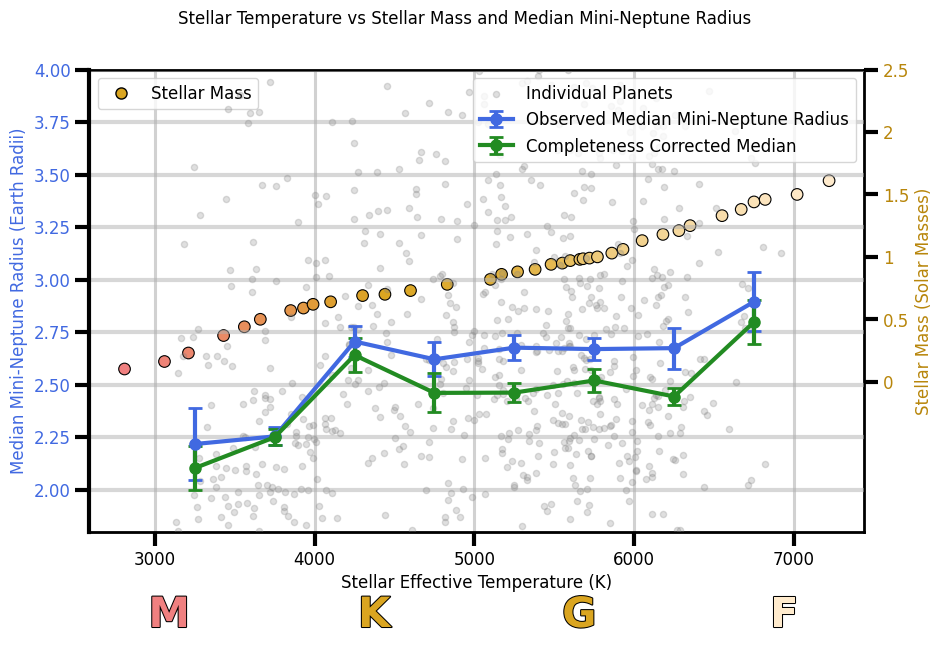

In [7]:
#### PRESENTATION VERSION ####

# Bootstrap error calculation
n_bootstrap = 1000

# Load TOI data for bootstrapping
TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')
TOIs = TOIs.dropna(subset=['st_teff', 'pl_rade'])
TOIs = TOIs[(TOIs['pl_rade'] > 1.8) & (TOIs['pl_rade'] < 4.0)]
TOIs = TOIs[(TOIs['pl_orbper'] > 0.6028) & (TOIs['pl_orbper'] < 25.1)]
if 'tfopwg_disp' in TOIs.columns:
    TOIs = TOIs[TOIs['tfopwg_disp'] != 'FP']
print(len(TOIs))

# Define temperature bins matching mean_median_df
bins_teff = [3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000]

planet_radii_medians = []
planet_radii_errors = []
bin_centers = []

for i in range(len(bins_teff)-1):
    bin_mask = (TOIs['st_teff'] >= bins_teff[i]) & (TOIs['st_teff'] < bins_teff[i+1])
    planet_radii = TOIs.loc[bin_mask, 'pl_rade']
    planet_radii_n = len(planet_radii)
    
    if planet_radii_n == 0:
        planet_radii_errors.append(np.nan)
        planet_radii_medians.append(np.nan)
        bin_centers.append((bins_teff[i] + bins_teff[i+1]) / 2)
        continue
    
    # Bootstrap resampling
    bootstrap_medians = []
    for _ in range(n_bootstrap):
        bootstrap_sample = planet_radii.sample(n=planet_radii_n, replace=True)
        bootstrap_medians.append(np.median(bootstrap_sample))
    
    planet_radii_error = np.std(bootstrap_medians)
    planet_radii_median = np.median(planet_radii)
    
    print(f"Teff {bins_teff[i]}-{bins_teff[i+1]} K: N={planet_radii_n}, Median={planet_radii_median:.2f}, Error={planet_radii_error:.3f} R_Earth")
    
    planet_radii_medians.append(planet_radii_median)
    planet_radii_errors.append(planet_radii_error)
    bin_centers.append((bins_teff[i] + bins_teff[i+1]) / 2)

print(f"\nTotal bins: {len(planet_radii_medians)}, {len(planet_radii_errors)}, {len(bin_centers)}")

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

import matplotlib.colors as mcolors

# Gradual color transition for scatter points
n_points = len(stellar_df)
colors = []
for i in range(n_points):
    ratio = i / (n_points - 1)
    if ratio <= 0.3:
        local_ratio = ratio / 0.3
        r = 240 + (218 - 240) * local_ratio
        g = 128 + (165 - 128) * local_ratio
        b = 128 + (32 - 128) * local_ratio
    else:
        local_ratio = (ratio - 0.3) / 0.7
        r = 218 + (255 - 218) * local_ratio
        g = 165 + (235 - 165) * local_ratio
        b = 32 + (205 - 32) * local_ratio
    colors.append((r/255, g/255, b/255))

from matplotlib.lines import Line2D
from matplotlib.patheffects import withStroke


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Stellar Mass',
                          markerfacecolor='goldenrod', markeredgecolor='black', markersize=8, linewidth=.1)]
ax1.scatter(stellar_df['Effective Temperature'], stellar_df['Mass'], 
           c=colors, edgecolor='black', linewidth=0.8, s=70, zorder = 3)
ax1.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax1.set_ylabel('Stellar Mass (Solar Masses)', color='darkgoldenrod', size=12)
ax1.tick_params(axis='y', labelcolor='darkgoldenrod')
ax1.set_ylim(-1.2,2.5)
# Show only positive y-ticks on the stellar-mass axis
ax1.set_yticks([t for t in ax1.get_yticks() if t >= 0])
ax1.set_yticklabels([f"{t:g}" for t in ax1.get_yticks() if t >= 0])

# Add colored spectral type labels to the bottom of the plot with black outline
outline = [withStroke(linewidth=1.5, foreground='black')]
xmin, xmax = ax1.get_xlim()
y_bottom = ax1.get_ylim()[0] - .5
x_positions = np.linspace(xmin + 500, xmax - 500, 4)
ax1.text(x_positions[0], y_bottom, 'M', color='lightcoral', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)
ax1.text(x_positions[1], y_bottom, 'K', color='goldenrod', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)
ax1.text(x_positions[2], y_bottom, 'G', color='goldenrod', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)
ax1.text(x_positions[3], y_bottom, 'F', color='blanchedalmond', fontsize=30, va='top', ha='center', fontweight='bold', path_effects=outline)

# Secondary y-axis for Median with error bars
ax2 = ax1.twinx()
# Force vertical grid lines from the shared x-axis
ax1.grid(True, axis='x', which='major', linewidth=2.2, alpha=0.6, color='0.7')
ax1.xaxis.grid(True, which='major', linewidth=2.2, alpha=0.6, color='0.7')
# Keep horizontal grid lines on the radius axis
ax2.grid(True, axis='y', which='major', linewidth=3, alpha=.5)
ax2.set_axisbelow(True)

# Add individual planet radii as grey transparent dots
ax2.scatter(TOIs['st_teff'], TOIs['pl_rade'], 
           color='grey', alpha=0.25, s=20, zorder=1, label='Individual Planets')

print(f"Uncorrected Bin centers: {bin_centers}, Medians: {planet_radii_medians}, Errors: {planet_radii_errors}")

ax2.errorbar(
    bin_centers, planet_radii_medians, yerr=planet_radii_errors,
    color='royalblue', label='Observed Median Mini-Neptune Radius', marker='o', 
    linestyle='-', markersize=8, linewidth=3, capsize=5, capthick=2, zorder=3
)
ax2.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='royalblue', size=12)
ax2.tick_params(axis='y', labelcolor='royalblue', size=12)
ax2.set_ylim(1.8, 4.0)

# Add completeness-corrected medians (green) in the same style
if 'corrected_mean_median_df' in globals():
    ax2.errorbar(
        corrected_mean_median_df['Teff Range Average'],
        corrected_mean_median_df['Weighted Median Radius (Earth Radii)'],
        yerr=corrected_mean_median_df['Weighted Median Error (Earth Radii)'],
        color='forestgreen', label='Completeness Corrected Median',
        marker='o', linestyle='-', markersize=8, linewidth=3,
        capsize=5, capthick=2, zorder=3
    )

# Flip y-axis positions: stellar mass axis to right, radius axis to left
ax1.yaxis.set_label_position('right')
ax1.yaxis.tick_right()
ax1.spines['right'].set_visible(True)
ax1.spines['left'].set_visible(False)

ax2.yaxis.set_label_position('left')
ax2.yaxis.tick_left()
ax2.spines['left'].set_position(('outward', 0))
ax2.spines['left'].set_visible(True)
ax2.spines['right'].set_visible(False)

fig.suptitle('Stellar Temperature vs Stellar Mass and Median Mini-Neptune Radius', size=12)
ax1.legend(handles=legend_elements, loc='upper left', fontsize=12)
ax2.legend(loc='upper right', fontsize=12)
ax1.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax1.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
ax2.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax2.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax1.spines.values():
    spine.set_linewidth(2)
ax2.spines['left'].set_linewidth(3)
plt.show()


fig.savefig('stellar_temp_vs_disk_mass_and_median_radius.png', dpi=300, bbox_inches='tight')

--- Slopes of Corrected Median Line ---
Slope between 1st & 3rd points (Stellar Mass ~0.38 to 0.68): 1.470
Slope between 3rd & 7th points (Stellar Mass ~0.68 to 1.27): -0.282
Slope between 7th & 8th points (Stellar Mass ~1.27 to 1.43): 2.498


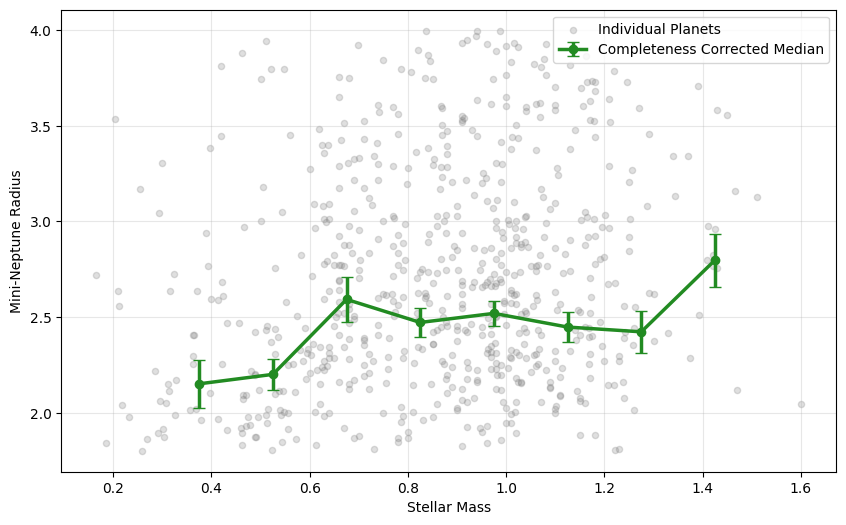

In [8]:

# Prepare TOI table with mass
TOIs_mass = TOIs.copy()
if 'mst' not in TOIs_mass.columns and 'st_mass' not in TOIs_mass.columns:
    TOIs_mass = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')

mass_col = 'mst' if 'mst' in TOIs_mass.columns else 'st_mass'

TOIs_mass = TOIs_mass.dropna(subset=['st_teff', 'pl_rade', mass_col])
TOIs_mass = TOIs_mass[(TOIs_mass['pl_rade'] > 1.8) & (TOIs_mass['pl_rade'] < 4.0)]
TOIs_mass = TOIs_mass[(TOIs_mass['pl_orbper'] > 0.6028) & (TOIs_mass['pl_orbper'] < 25.1)]
if 'tfopwg_disp' in TOIs_mass.columns:
    TOIs_mass = TOIs_mass[TOIs_mass['tfopwg_disp'] != 'FP']

# Build 8 mass bins (same count as temperature bins)
n_bins = len(bins_teff) - 1
mass_edges = np.linspace(0.3, 1.5, n_bins + 1)
if len(mass_edges) < 3:
    mass_edges = np.linspace(TOIs_mass[mass_col].min(), TOIs_mass[mass_col].max(), n_bins + 1)

def weighted_median(vals, weights):
    vals = np.asarray(vals)
    weights = np.asarray(weights)
    if len(vals) == 0 or np.nansum(weights) <= 0:
        return np.nan
    s = np.argsort(vals)
    vals_s = vals[s]
    w_s = weights[s]
    cdf = np.cumsum(w_s)
    return vals_s[np.searchsorted(cdf, 0.5 * cdf[-1])]

# Observed medians + bootstrap errors (unweighted)
obs_centers, obs_medians, obs_errs = [], [], []
for i in range(len(mass_edges) - 1):
    lo, hi = mass_edges[i], mass_edges[i + 1]
    m = TOIs_mass[(TOIs_mass[mass_col] >= lo) & (TOIs_mass[mass_col] < hi)]
    vals = m['pl_rade'].values
    obs_centers.append(0.5 * (lo + hi))
    if len(vals) == 0:
        obs_medians.append(np.nan)
        obs_errs.append(np.nan)
        continue
    obs_medians.append(np.median(vals))
    boot = [np.median(np.random.choice(vals, size=len(vals), replace=True)) for _ in range(n_bootstrap)]
    obs_errs.append(np.std(boot))

# Corrected medians + bootstrap errors (weighted)
mass_map = TOIs_mass[['toi', mass_col]].drop_duplicates(subset='toi')
merged_mass = merged_df.merge(mass_map, on='toi', how='left').dropna(subset=[mass_col, 'pl_rade', 'weight'])

cor_centers, cor_medians, cor_errs = [], [], []
for i in range(len(mass_edges) - 1):
    lo, hi = mass_edges[i], mass_edges[i + 1]
    m = merged_mass[(merged_mass[mass_col] >= lo) & (merged_mass[mass_col] < hi)]
    vals = m['pl_rade'].values
    w = m['weight'].values
    cor_centers.append(0.5 * (lo + hi))
    if len(vals) == 0 or np.nansum(w) <= 0:
        cor_medians.append(np.nan)
        cor_errs.append(np.nan)
        continue
    cor_medians.append(weighted_median(vals, w))
    idx = np.arange(len(vals))
    boot = []
    for _ in range(n_bootstrap):
        bidx = np.random.choice(idx, size=len(idx), replace=True)
        boot.append(weighted_median(vals[bidx], w[bidx]))
    cor_errs.append(np.nanstd(boot))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)

ax.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'],
           color='grey', alpha=0.25, s=20, label='Individual Planets')


ax.errorbar(cor_centers, cor_medians, yerr=cor_errs,
            color='forestgreen', marker='o', linestyle='-',
            linewidth=2.5, capsize=4, label='Completeness Corrected Median')

# Calculate slopes for specific segments of the green line (Completeness Corrected Median)
slope1_3 = (cor_medians[2] - cor_medians[0]) / (cor_centers[2] - cor_centers[0])
slope3_7 = (cor_medians[6] - cor_medians[2]) / (cor_centers[6] - cor_centers[2])
slope7_8 = (cor_medians[7] - cor_medians[6]) / (cor_centers[7] - cor_centers[6])

print("--- Slopes of Corrected Median Line ---")
print(f"Slope between 1st & 3rd points (Stellar Mass ~{cor_centers[0]:.2f} to {cor_centers[2]:.2f}): {slope1_3:.3f}")
print(f"Slope between 3rd & 7th points (Stellar Mass ~{cor_centers[2]:.2f} to {cor_centers[6]:.2f}): {slope3_7:.3f}")
print(f"Slope between 7th & 8th points (Stellar Mass ~{cor_centers[6]:.2f} to {cor_centers[7]:.2f}): {slope7_8:.3f}")

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

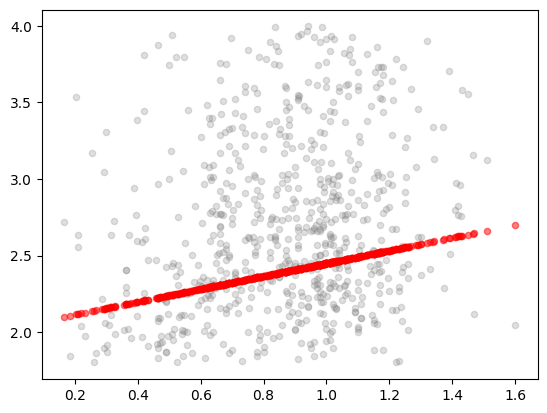

In [9]:
plt.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'], color='grey', alpha=0.25, s=20, label='Individual Planets')

x_sorted = TOIs_mass[mass_col].sort_values().values

lower_bound = 2.1
upper_bound = 2.7

# Linear interpolation: y goes from lower_bound to upper_bound
# as x goes from x_sorted.min() to x_sorted.max()
x_min, x_max = x_sorted.min(), x_sorted.max()
straight_line = lower_bound + (x_sorted - x_min) / (x_max - x_min) * (upper_bound - lower_bound)

plt.scatter(x_sorted, straight_line, color='red', alpha=0.5, s=20, label='Reference Line (y=1)')

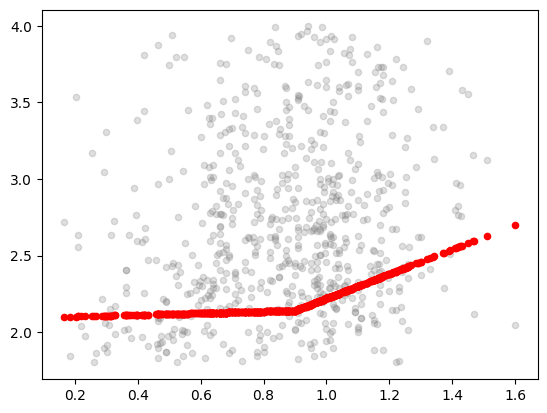

In [10]:
plt.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'], color='grey', alpha=0.25, s=20, label='Individual Planets')


x = np.sort(TOIs_mass[mass_col].values)

x0 = x.min()
x1 = .9
x2 = x.max()

y0 = 2.1
y2 = 2.7

slope2 = 0.8   # choose this

# Solve for slope1 so the line ends at y2
slope1 = (y2 - y0 - slope2 * (x2 - x1)) / (x1 - x0)

y = np.empty_like(x)

mask = x <= x1
y[mask] = y0 + slope1 * (x[mask] - x0)

y_break = y0 + slope1 * (x1 - x0)

y[~mask] = y_break + slope2 * (x[~mask] - x1)

plt.scatter(x, y, color='red', s=20, label='Fitted Line')

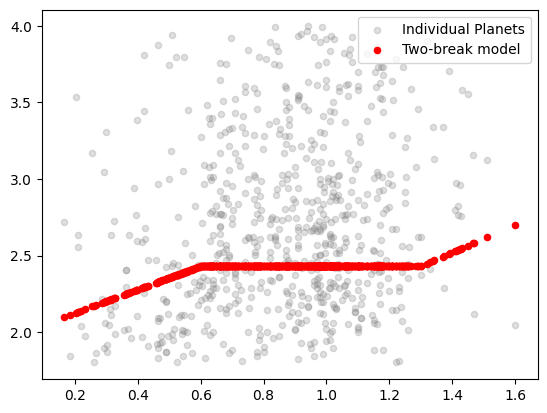

In [11]:
plt.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'], color='grey', alpha=0.25, s=20, label='Individual Planets')

x = np.sort(TOIs_mass[mass_col].values)

# Endpoints
x0 = x.min()
x3 = x.max()

y0 = 2.1
y3 = 2.7

# Break locations
x1 = 0.6
x2 = 1.3

# Choose these slopes
slope2 = 0
slope3 = 0.90

# Solve for slope1 so the line ends at y3
slope1 = (
    y3 - y0
    - slope2 * (x2 - x1)
    - slope3 * (x3 - x2)
) / (x1 - x0)

# Build the piecewise line
y = np.empty_like(x)

mask1 = x <= x1
mask2 = (x > x1) & (x <= x2)
mask3 = x > x2

# First segment
y[mask1] = y0 + slope1 * (x[mask1] - x0)

# Value at first break
y1 = y0 + slope1 * (x1 - x0)

# Second segment
y[mask2] = y1 + slope2 * (x[mask2] - x1)

# Value at second break
y2 = y1 + slope2 * (x2 - x1)

# Third segment
y[mask3] = y2 + slope3 * (x[mask3] - x2)

plt.scatter(x, y, color='red', s=20, label='Two-break model')
plt.legend()

N data points: 677

Model                 chi2     p-value   dof    reduced chi2
Straight ramp       75.638           1   675          0.1121
One-break           75.207           1   674          0.1116
Two-break           75.416           1   673          0.1121


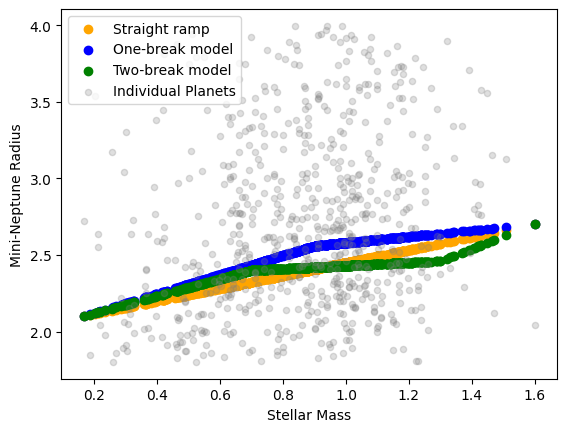

In [12]:
# Compare the three model fits (straight ramp, one-break, two-break) to the data
# via scipy.stats.chisquare. Each model predicts a mini-Neptune radius as a function
# of stellar mass; we evaluate it at every observed mass and compare to pl_rade.
from scipy.stats import chisquare

# Observed data (align mass and radius on the same rows, drop any NaNs)
_fit = TOIs_mass[[mass_col, 'pl_rade']].dropna()
x_obs = _fit[mass_col].values
y_obs = _fit['pl_rade'].values
x_min, x_max = x_obs.min(), x_obs.max()

# --- Model A: single straight ramp (cell 52387c8d) ---
def model_straight(x):
    lower_bound, upper_bound = 2.1, 2.7
    return lower_bound + (x - x_min) / (x_max - x_min) * (upper_bound - lower_bound)

# --- Model B: one-break piecewise line (cell 91092e8c) ---
def model_one_break(x):
    x0, x1, x2 = x_min, 0.9, x_max
    y0, y2 = 2.1, 2.7
    slope2 = 0.2
    slope1 = (y2 - y0 - slope2 * (x2 - x1)) / (x1 - x0)
    y_break = y0 + slope1 * (x1 - x0)
    return np.where(x <= x1, y0 + slope1 * (x - x0), y_break + slope2 * (x - x1))

# --- Model C: two-break piecewise line (cell 83175ba8) ---
def model_two_break(x):
    x0, x3 = x_min, x_max
    y0, y3 = 2.1, 2.7
    x1, x2 = 0.7, 1.3
    slope2, slope3 = 0.1, 0.80
    slope1 = (y3 - y0 - slope2 * (x2 - x1) - slope3 * (x3 - x2)) / (x1 - x0)
    y1 = y0 + slope1 * (x1 - x0)
    y2 = y1 + slope2 * (x2 - x1)
    return np.select(
        [x <= x1, (x > x1) & (x <= x2), x > x2],
        [y0 + slope1 * (x - x0), y1 + slope2 * (x - x1), y2 + slope3 * (x - x2)]
    )

# Number of free parameters per model (for reduced chi-square / dof bookkeeping)
models = {
    'Straight ramp':  (model_straight,  2),   # y0, y1
    'One-break':      (model_one_break, 3),   # y0, y2, slope2
    'Two-break':      (model_two_break, 4),   # y0, y3, slope2, slope3
}

print(f"N data points: {len(y_obs)}\n")
print(f"{'Model':<14}{'chi2':>12}{'p-value':>12}{'dof':>6}{'reduced chi2':>16}")

for name, (func, n_params) in models.items():
    y_exp = func(x_obs)
    # scipy.chisquare requires sum(f_exp) == sum(f_obs); rescale expected to the
    # observed total so the statistic reflects the shape mismatch, not a normalization offset.
    y_exp_scaled = y_exp * (y_obs.sum() / y_exp.sum())
    chi2, p = chisquare(f_obs=y_obs, f_exp=y_exp_scaled)
    dof = len(y_obs) - n_params
    print(f"{name:<14}{chi2:>12.3f}{p:>12.3g}{dof:>6}{chi2/dof:>16.4f}")

#print("\nLower chi2 / reduced chi2 => better fit to the data.")

plt.scatter(x_obs, model_straight(x_obs), color='orange', label='Straight ramp')
plt.scatter(x_obs, model_one_break(x_obs), color='blue', label='One-break model')
plt.scatter(x_obs, model_two_break(x_obs), color='green', label='Two-break model')
plt.scatter(x_obs, y_obs, color='grey', alpha=0.25, s=20, label='Individual Planets')
plt.xlabel('Stellar Mass')
plt.ylabel('Mini-Neptune Radius')
plt.legend()    

In [13]:
# Completeness-weighted chi-square (injection/recovery weights).
# Each detected planet's `weight` (= detection_inverse * transit_inverse) says how many
# planets it represents in the true population, so it MULTIPLIES its squared residual.
# scipy.chisquare can't take weights, so we form the weighted statistic by hand.
# Reuses model_straight / model_one_break / model_two_break and the `models` dict above.

# Pull the inj/rec weight onto each TOI by matching on `toi` (merged_df has one row per TOI)
_wt = merged_df[['toi', 'weight']].drop_duplicates(subset='toi')
_w = TOIs_mass[[mass_col, 'pl_rade', 'toi']].merge(_wt, on='toi', how='left')
_w = _w.dropna(subset=[mass_col, 'pl_rade', 'weight'])
_w = _w[_w['weight'] > 0]

xw = _w[mass_col].values
yw = _w['pl_rade'].values
w  = _w['weight'].values

print(f"N data points (with valid weight): {len(yw)}")
print(f"Sum of weights (effective population size): {w.sum():.1f}\n")
print(f"{'Model':<14}{'weighted chi2':>16}{'dof':>6}{'reduced chi2':>16}")
print("-" * 52)

for name, (func, n_params) in models.items():
    y_exp = func(xw)
    chi2_w = np.sum(w * (yw - y_exp) ** 2)   # completeness-weighted sum of squared residuals
    dof = len(yw) - n_params
    print(f"{name:<14}{chi2_w:>16.3f}{dof:>6}{chi2_w/dof:>16.4f}")

print("\nLower weighted chi2 => model better matches the completeness-corrected population.")
print("(inj/rec weights are importance weights, so this is a weighted sum of squared")
print(" residuals for ranking models, not calibrated to the chi-square distribution -> no p-value.)")


N data points (with valid weight): 677
Sum of weights (effective population size): 21883.1

Model            weighted chi2   dof    reduced chi2
----------------------------------------------------
Straight ramp         6327.289   675          9.3738
One-break             5774.371   674          8.5673
Two-break             6234.729   673          9.2641

Lower weighted chi2 => model better matches the completeness-corrected population.
(inj/rec weights are importance weights, so this is a weighted sum of squared
 residuals for ranking models, not calibrated to the chi-square distribution -> no p-value.)


N bins (with valid median/error): 8

Model                 chi2     p-value   dof    reduced chi2
------------------------------------------------------------
Straight ramp       12.971      0.0435     6          2.1618
One-break           14.486      0.0128     5          2.8971
Two-break           10.647      0.0308     4          2.6618

Lower reduced chi2 / higher p-value => model better matches the binned
completeness-corrected medians.


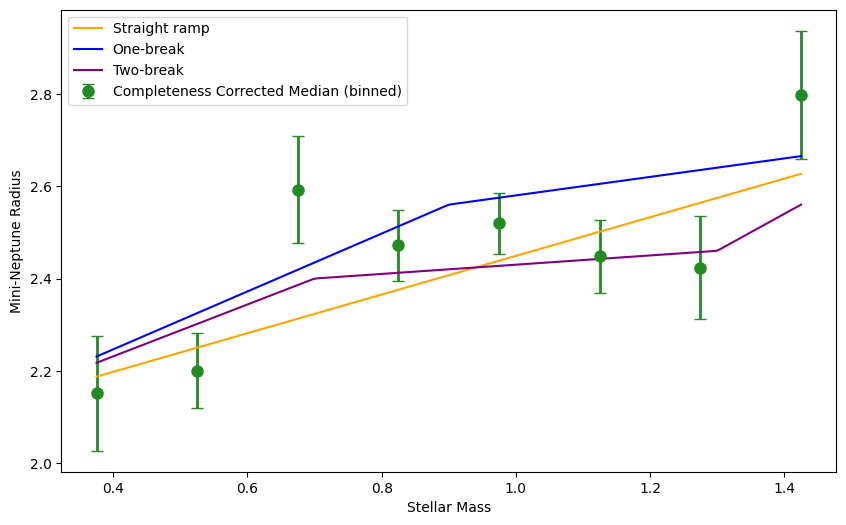

In [14]:
# Chi-square fits to the BINNED data (the 8 mass-bin medians from cell 178beddb),
# rather than to every individual TOI. Each bin has a real uncertainty (cor_errs,
# from bootstrap resampling of the weighted median), so this is a proper
# chi2 = sum(((y_obs - y_model) / sigma)^2) with a calibrated p-value -- unlike the
# per-planet weighted sum in the previous cell, which isn't on the chi-square scale.
from scipy.stats import chi2 as chi2_dist

cor_centers_arr = np.array(cor_centers)
cor_medians_arr = np.array(cor_medians)
cor_errs_arr = np.array(cor_errs)

# Drop any empty bins (nan median/error)
_valid = ~(np.isnan(cor_medians_arr) | np.isnan(cor_errs_arr) | (cor_errs_arr == 0))
xb = cor_centers_arr[_valid]
yb = cor_medians_arr[_valid]
eb = cor_errs_arr[_valid]

print(f"N bins (with valid median/error): {len(yb)}\n")
print(f"{'Model':<14}{'chi2':>12}{'p-value':>12}{'dof':>6}{'reduced chi2':>16}")
print("-" * 60)

binned_fit_results = {}
for name, (func, n_params) in models.items():
    y_model = func(xb)
    chi2_val = np.sum(((yb - y_model) / eb) ** 2)
    dof = len(yb) - n_params
    p_val = chi2_dist.sf(chi2_val, dof) if dof > 0 else np.nan
    binned_fit_results[name] = (chi2_val, dof, p_val)
    print(f"{name:<14}{chi2_val:>12.3f}{p_val:>12.3g}{dof:>6}{chi2_val/dof:>16.4f}")

print("\nLower reduced chi2 / higher p-value => model better matches the binned")
print("completeness-corrected medians.")

# Plot the three models against the binned data with error bars
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(xb, yb, yerr=eb, fmt='o', color='forestgreen', capsize=4,
            markersize=8, linewidth=2, label='Completeness Corrected Median (binned)')

x_line = np.linspace(xb.min(), xb.max(), 200)
ax.plot(x_line, model_straight(x_line), color='orange', label='Straight ramp')
ax.plot(x_line, model_one_break(x_line), color='blue', label='One-break')
ax.plot(x_line, model_two_break(x_line), color='purple', label='Two-break')

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

Model                 chi2   dof    reduced chi2     p-value
Straight ramp       12.109     6          2.0181      0.0596
One-break            8.207     4          2.0518      0.0843
Two-break            2.699     2          1.3493       0.259


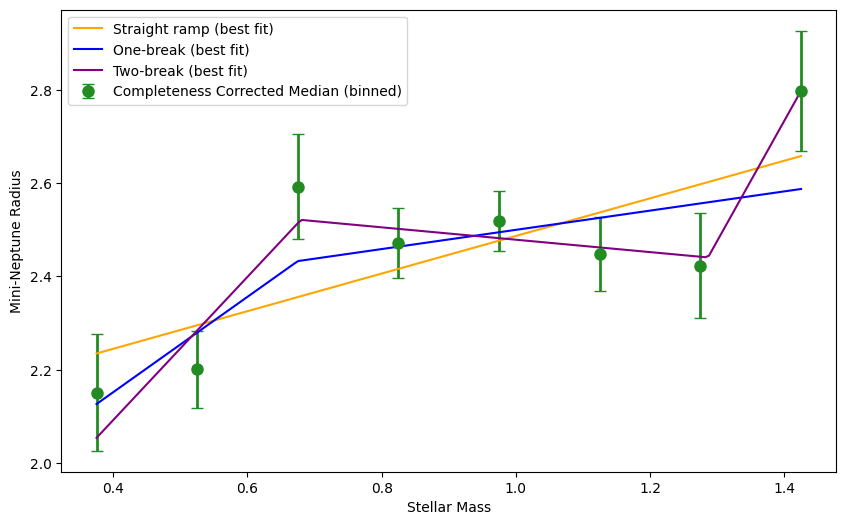

In [28]:
# ===========================================================================
# GOAL
# ---------------------------------------------------------------------------
# The cells above (52387c8d, 91092e8c, 83175ba8) used HAND-PICKED breakpoints
# and slopes for the straight/one-break/two-break lines -- e.g. the one-break
# model always broke at stellar mass = 0.9 and always used slope2 = 0.2,
# whether or not that's actually where the data bends.
#
# This cell instead lets scipy find the best possible version of each shape:
# it searches over breakpoint locations AND slopes to minimize chi-square
# against the binned data (xb, yb, eb from the previous cell). That way when
# we compare "straight vs one-break vs two-break" later (AIC/BIC cell), we're
# comparing each shape's BEST case, not an arbitrary guess.
# ===========================================================================
from scipy.optimize import curve_fit

# x0_fit/x3_fit anchor the piecewise lines to the first/last binned mass point.
# slope_guess is just a straight-line-between-endpoints estimate, used as the
# starting guess (p0) for curve_fit -- it doesn't have to be accurate, curve_fit
# will refine it, it just needs to be in the right ballpark so the optimizer
# doesn't get lost.
x0_fit, x3_fit = xb.min(), xb.max()
slope_guess = (yb[-1] - yb[0]) / (x3_fit - x0_fit)

# --- Straight line: y = y0 + slope*(x - x0) ---
# 2 free parameters: y0 (starting height) and slope.
def fit_straight(x, y0, slope):
    return y0 + slope * (x - x0_fit)

# --- One-break piecewise line: y0 at x0, ONE break at a free location x1 ---
# 4 free parameters: y0, x1 (break location), slope1 (before break), slope2 (after).
# Unlike the hand-picked version above, x1 is no longer fixed at 0.9 -- curve_fit
# decides where the bend actually belongs.
def fit_one_break(x, y0, x1, slope1, slope2):
    y1 = y0 + slope1 * (x1 - x0_fit)   # height of the line right at the break
    return np.where(x <= x1, y0 + slope1 * (x - x0_fit), y1 + slope2 * (x - x1))

# --- Two-break piecewise line: y0 at x0, breaks at free x1 < x2 ---
# 6 free parameters: y0, x1, x2 (both break locations), slope1/slope2/slope3
# (one slope per segment). More flexible than one-break, but also more prone
# to overfitting with only 8 binned points -- that tradeoff gets checked
# properly in the AIC/BIC cell below.
def fit_two_break(x, y0, x1, x2, slope1, slope2, slope3):
    y1 = y0 + slope1 * (x1 - x0_fit)   # height at the first break
    y2 = y1 + slope2 * (x2 - x1)       # height at the second break
    return np.select(
        [x <= x1, (x > x1) & (x <= x2), x > x2],
        [y0 + slope1 * (x - x0_fit), y1 + slope2 * (x - x1), y2 + slope3 * (x - x2)]
    )

# Each entry is (model function, initial guess p0, parameter bounds).
# Bounds keep the break locations (x1, x2) inside the actual data range
# [x0_fit, x3_fit] -- otherwise curve_fit could "solve" the fit by placing a
# break outside the data, which is meaningless. Slopes and y0 are left
# unbounded (-inf, inf) since there's no physical reason to restrict them.
fit_specs = {
    'Straight ramp': (
        fit_straight, [yb[0], slope_guess],
        (-np.inf, np.inf),
    ),
    'One-break': (
        fit_one_break, [yb[0], 0.5 * (x0_fit + x3_fit), slope_guess, slope_guess],
        ([-np.inf, x0_fit, -np.inf, -np.inf], [np.inf, x3_fit, np.inf, np.inf]),
    ),
    'Two-break': (
        fit_two_break,
        [yb[0], x0_fit + (x3_fit - x0_fit) / 3, x0_fit + 2 * (x3_fit - x0_fit) / 3, slope_guess, slope_guess, slope_guess],
        ([-np.inf, x0_fit, x0_fit, -np.inf, -np.inf, -np.inf], [np.inf, x3_fit, x3_fit, np.inf, np.inf, np.inf]),
    ),
}
best_fit_results = {}
print(f"{'Model':<14}{'chi2':>12}{'dof':>6}{'reduced chi2':>16}{'p-value':>12}")

for name, (func, p0, bounds) in fit_specs.items():
    # curve_fit does the actual optimization: it searches parameter space to
    # minimize sum(((yb - func(xb, *params)) / eb)**2) -- i.e. weighted
    # least-squares, same statistic as chi-square. sigma=eb weights each bin
    # by its bootstrap uncertainty (see the earlier "where are the weights"
    # question -- same mechanism as before, just now driving an optimizer
    # instead of evaluating a fixed model). absolute_sigma=True tells it eb
    # is a real physical uncertainty (not just a relative weight), which
    # matters for how pcov (the parameter covariance matrix) gets scaled.
    # We don't use pcov here, but it's what you'd read parameter uncertainties
    # off of if you wanted error bars on the fitted slopes/breakpoints.
    popt, pcov = curve_fit(func, xb, yb, p0=p0, sigma=eb, absolute_sigma=False, bounds=bounds)

    # Re-evaluate chi-square at the best-fit parameters (popt) -- same formula
    # as the hand-picked-model cell above, just with the OPTIMIZED parameters
    # plugged in instead of guessed ones.
    y_model = func(xb, *popt)
    chi2_val = np.sum(((yb - y_model) / eb) ** 2)
    dof = len(yb) - len(popt)   # degrees of freedom = data points minus fitted parameters
    p_val = chi2_dist.sf(chi2_val, dof) if dof > 0 else np.nan
    best_fit_results[name] = {'popt': popt, 'chi2': chi2_val, 'dof': dof, 'p': p_val}
    print(f"{name:<14}{chi2_val:>12.3f}{dof:>6}{chi2_val/dof:>16.4f}{p_val:>12.3g}")

# print("\nBest-fit parameters:")
# for name, res in best_fit_results.items():
#     print(f"  {name}: {np.round(res['popt'], 3)}")

# Plot the binned data with each best-fit curve overlaid, so you can eyeball
# how much (or little) each shape actually bends once it's allowed to fit freely.
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(xb, yb, yerr=eb, fmt='o', color='forestgreen', capsize=4,
            markersize=8, linewidth=2, label='Completeness Corrected Median (binned)')

x_line = np.linspace(x0_fit, x3_fit, 200)
colors = {'Straight ramp': 'orange', 'One-break': 'blue', 'Two-break': 'purple'}
for name, (func, _, _) in fit_specs.items():
    ax.plot(x_line, func(x_line, *best_fit_results[name]['popt']), color=colors[name], label=f'{name} (best fit)')

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

In [ ]:
# AIC/BIC comparison of the three best-fit models above.
# For weighted-least-squares fits with known Gaussian errors, chi2 IS -2*lnL up to
# an additive constant that's the same for every model here (it only depends on the
# data/errors, not on the model), so it's valid to build AIC/BIC directly from chi2:
#   AIC = chi2 + 2k
#   BIC = chi2 + k*ln(n)
# where k = number of free parameters and n = number of binned data points.
# Unlike the raw chi2/p-value comparison, AIC/BIC explicitly penalize the extra
# breakpoint parameters, so they answer "is the improved fit worth the added
# complexity?" rather than just "does it fit better?".
n_data = len(yb)

print(f"n data points = {n_data}\n")
print(f"{'Model':<14}{'k':>4}{'chi2':>10}{'AIC':>10}{'BIC':>10}")
print("-" * 48)

aic_bic = {}
for name, res in best_fit_results.items():
    k = len(res['popt'])
    chi2_val = res['chi2']
    aic = chi2_val + 2 * k
    bic = chi2_val + k * np.log(n_data)
    aic_bic[name] = {'k': k, 'chi2': chi2_val, 'AIC': aic, 'BIC': bic}
    print(f"{name:<14}{k:>4}{chi2_val:>10.3f}{aic:>10.3f}{bic:>10.3f}")

best_aic = min(v['AIC'] for v in aic_bic.values())
best_bic = min(v['BIC'] for v in aic_bic.values())

print(f"\n{'Model':<14}{'dAIC':>10}{'dBIC':>10}{'Akaike weight':>16}")
print("-" * 50)

# Akaike weights: relative likelihood of each model given the candidate set,
# normalized to sum to 1. exp(-0.5*dAIC) is the relative likelihood; dividing by
# the sum of all of them turns that into a probability-like weight.
rel_likelihoods = {name: np.exp(-0.5 * (v['AIC'] - best_aic)) for name, v in aic_bic.items()}
norm = sum(rel_likelihoods.values())

for name, v in aic_bic.items():
    dAIC = v['AIC'] - best_aic
    dBIC = v['BIC'] - best_bic
    weight = rel_likelihoods[name] / norm
    print(f"{name:<14}{dAIC:>10.3f}{dBIC:>10.3f}{weight:>16.3f}")

print("\nRules of thumb (Burnham & Anderson): dAIC < 2 -> substantial support,")
print("4-7 -> considerably less support, > 10 -> essentially no support.")
print("BIC penalizes extra parameters more heavily than AIC (log(n) vs 2),")
print("so it favors simpler models more strongly, especially with few data points.")